# ToMATo explanation

Figures for explaining ToMATo, built step by step on a small 2-D dataset.

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sp
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.collections import LineCollection
from matplotlib.colors import to_rgba
from mpl_toolkits.mplot3d.art3d import Line3DCollection
from scipy.interpolate import PchipInterpolator
from scipy.ndimage import maximum_filter, minimum_filter
from scipy.spatial import cKDTree
from scipy.special import logsumexp, softmax
from sklearn import datasets
from sklearn.preprocessing import StandardScaler

## Data

scikit-learn's anisotropic blobs, as in its clustering comparison: three Gaussian blobs, sheared, then standardized.

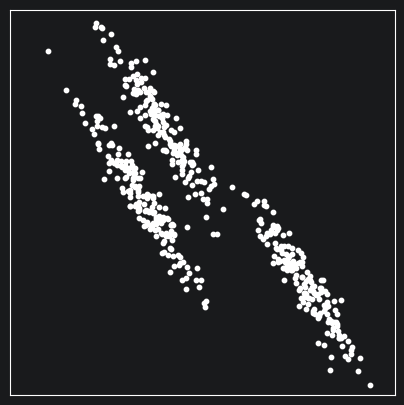

In [2]:
N_SAMPLES = 500
X, y = datasets.make_blobs(n_samples=N_SAMPLES, random_state=170)
X = StandardScaler().fit_transform(X @ np.array([[0.6, -0.6], [-0.4, 0.8]]))

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[:, 0], X[:, 1], s=10, color="1.0")
ax.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), aspect="equal", xticks=(), yticks=())
plt.show()

## Density

Each point's density as in our ToMATo runs: the log of a distance-to-measure estimate, from the mean squared
distance to the point's K_DENS nearest neighbors. A point in a tight crowd scores high. It is one number per
point, not a smooth surface, so each point is drawn at its own height on a stem above its place in the plane.

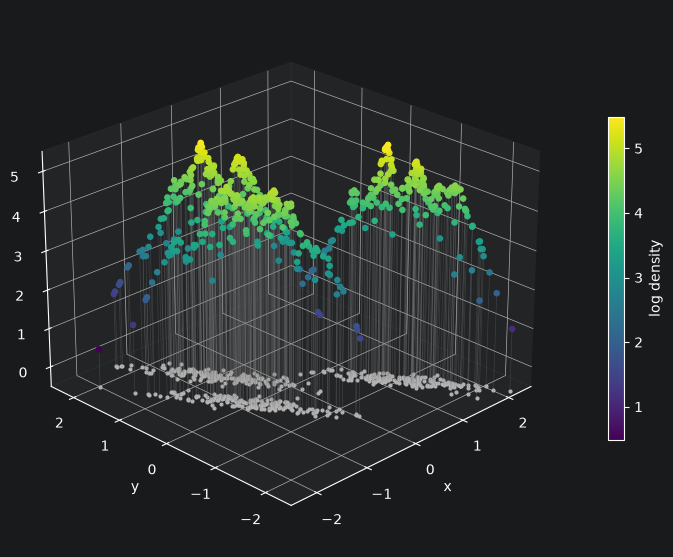

In [3]:
K_DENS = 15    # neighbors in the density estimate, the point itself excluded


def log_dtm(X, k):
    """Log-DTM density per point: -(dim / 2) log of the mean squared distance to the k nearest neighbors, the
    estimate density_and_graphs makes in tomato_nemi (where dim = 3)."""
    dist = cKDTree(X).query(X, k=k + 1)[0][:, 1:]
    return -(X.shape[1] / 2) * np.log(np.mean(dist ** 2, axis=1))


density = log_dtm(X, K_DENS)
floor = density.min() - 0.2 * np.ptp(density)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(X[:, 0], X[:, 1], np.full(len(X), floor), s=4, color="0.7", depthshade=False)
ax.add_collection3d(Line3DCollection(np.stack([np.c_[X, np.full(len(X), floor)], np.c_[X, density]], axis=1),
                                     colors="0.5", linewidths=0.4, alpha=0.35))
points = ax.scatter(X[:, 0], X[:, 1], density, c=density, cmap="viridis", s=14, depthshade=False)
ax.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), zlim=(floor, density.max()), xlabel="x", ylabel="y",
       zlabel="log density")
ax.view_init(elev=25, azim=-135)
fig.colorbar(points, ax=ax, shrink=0.6, pad=0.08, label="log density")
plt.show()

## Persistence

The density threshold α sweeps down from the densest point. Only points at or above α are in, joined by the kNN
graph ToMATo uses, so each connected group grows from its own peak. A peak appears (star) when α reaches it; when
two groups touch, the one with the lower peak dies there (ring) and joins the higher one, the elder rule. On the
right, each peak drops from the diagonal y = x as α falls, riding the horizontal α line, and stops where it
merges; its distance below the diagonal, peak density minus the density where it merged, is its persistence.
Peaks that never merge, one per piece of the graph, end on the strip below.

14 peaks, 1 never merge


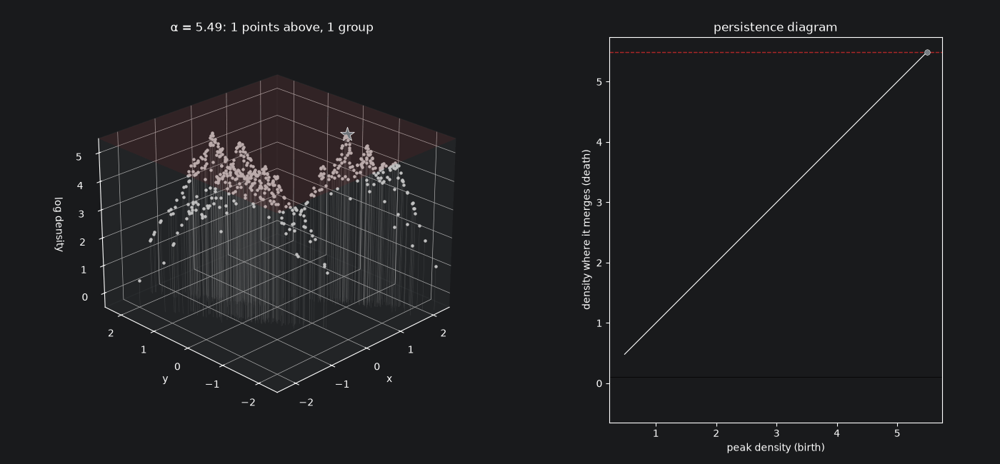

In [4]:
K_GRAPH = 10                    # neighbors in the graph, the point itself excluded
N_FRAMES, HOLD, FPS = 80, 16, 8   # frames sweeping alpha, frames holding the end, frames per second
FLASH = 4                       # frames a new peak's star or a merge's ring stays on
GIF_FILE = "tomato_persistence.gif"
PALETTE = ["#377eb8", "#ff7f00", "#4daf4a", "#f781bf", "#a65628", "#984ea3", "#e41a1c", "#dede00"]
FG = plt.rcParams["text.color"]   # outlines, rings and the zero line, visible on light or dark themes

nbrs = cKDTree(X).query(X, k=K_GRAPH + 1)[1][:, 1:]
A = sp.csr_matrix((np.ones(nbrs.size), nbrs.ravel(), np.arange(0, nbrs.size + 1, K_GRAPH)), shape=(len(X), len(X)))
graph = (A + A.T).tocsr()

# One pass from the densest point down.  A point with no neighbor above alpha starts a group at a peak; otherwise it
# joins its neighbors' groups, and where it touches several, each group but the one with the highest peak dies
# there (the elder rule).  A group's root is its peak, and each frame keeps every point's group (-1: below alpha).
order = np.argsort(-density, kind="stable")
alphas = np.linspace(density.max(), density.min(), N_FRAMES)
n_above = np.searchsorted(-density[order], -alphas, side="right")
parent = np.full(len(X), -1)
born, died = {}, {}             # peak -> step it appeared at; peak -> (saddle point, step it merged at)
groups = np.empty((N_FRAMES, len(X)), dtype=int)


def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


f = 0
for step, i in enumerate(order):
    parent[i] = i
    roots = {find(j) for j in graph.indices[graph.indptr[i]:graph.indptr[i + 1]] if parent[j] >= 0 and j != i}
    if roots:
        elder = max(roots, key=lambda r: density[r])
        parent[i] = elder
        for r in roots - {elder}:
            parent[r] = elder
            died[r] = (i, step)
    else:
        born[i] = step
    while f < N_FRAMES and n_above[f] == step + 1:
        groups[f] = [find(p) if parent[p] >= 0 else -1 for p in range(len(X))]
        f += 1

peaks = np.array(list(born))
death = np.array([density[died[p][0]] if p in died else -np.inf for p in peaks])
birth_frame = dict(zip(peaks, np.searchsorted(n_above, [born[p] + 1 for p in peaks])))
death_frame = {p: np.searchsorted(n_above, s + 1) for p, (_, s) in died.items()}
# the most prominent peaks take the palette, the rest pastels
color = {}
for rank, p in enumerate(peaks[np.argsort(-(density[peaks] - death), kind="stable")]):
    color[p] = to_rgba(PALETTE[rank] if rank < len(PALETTE) else plt.cm.Pastel2(rank % 8))
print(f"{len(peaks)} peaks, {len(peaks) - len(died)} never merge")

floor = density.min() - 0.2 * np.ptp(density)
stems = np.stack([np.c_[X, np.full(len(X), floor)], np.c_[X, density]], axis=1)
plane_x, plane_y = np.meshgrid([-2.5, 2.5], [-2.5, 2.5])
lo, hi = density.min(), density.max()
pad = 0.05 * (hi - lo)
y_inf = lo - 3 * pad            # height of the strip for never-merging peaks, below every death

fig = plt.figure(figsize=(14, 6.5))
grid = fig.add_gridspec(1, 2, width_ratios=[1.4, 1], left=0.0, right=0.97, bottom=0.09, top=0.92, wspace=0.08)
ax3 = fig.add_subplot(grid[0], projection="3d")
axd = fig.add_subplot(grid[1])


def draw(frame):
    f = min(frame, N_FRAMES - 1)
    end = frame >= N_FRAMES
    alpha, g = alphas[f], groups[f]
    above = g >= 0
    ax3.cla()
    ax3.add_collection3d(Line3DCollection(stems, colors="0.6", linewidths=0.3, alpha=0.25))
    ax3.scatter(X[~above, 0], X[~above, 1], density[~above], s=5, color="0.75", depthshade=False)
    ax3.scatter(X[above, 0], X[above, 1], density[above], s=14, color=[color[r] for r in g[above]], depthshade=False)
    ax3.plot_surface(plane_x, plane_y, np.full((2, 2), alpha), color="tab:red", alpha=0.12, linewidth=0)
    new = [p for p in peaks if f - FLASH < birth_frame[p] <= f]
    merged = [died[p][0] for p in died if f - FLASH < death_frame[p] <= f]
    ax3.scatter(X[new, 0], X[new, 1], density[new], s=220, marker="*", color=[color[p] for p in new],
                edgecolors=FG, linewidths=0.6, depthshade=False)
    ax3.scatter(X[merged, 0], X[merged, 1], density[merged], s=160, facecolors="none", edgecolors=FG,
                linewidths=1.2, depthshade=False)
    ax3.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), zlim=(floor, hi), xlabel="x", ylabel="y", zlabel="log density")
    ax3.view_init(elev=25, azim=-135)
    n_groups = len(set(g[above]))
    ax3.set_title(f"α = {alpha:.2f}: {above.sum()} points above, {n_groups} group{'s' * (n_groups != 1)}",
                  fontsize=12)

    # each peak at (birth, death): its persistence is its distance below the diagonal y = x, and a peak still
    # alive sits on the alpha line, which moves straight down
    axd.cla()
    axd.plot([lo, hi], [lo, hi], color="white", lw=0.8)
    axd.axhline(y_inf + 1.5 * pad, color="0.0", lw=0.5)
    if not end:
        axd.axhline(alpha, color="tab:red", ls="--", lw=1)
    for p, d in zip(peaks, death):
        if birth_frame[p] > f:
            continue
        dead = p in died and death_frame[p] <= f
        if dead:
            y = d
        else:
            y = y_inf if end else alpha
        if not dead:
            axd.plot([density[p], density[p]], [density[p], y], color=color[p], lw=1.4)
        axd.scatter(density[p], y, s=60 if end and not dead else 30, color=color[p], edgecolors=FG, linewidths=0.4,
                    marker="^" if end and not dead else "o", alpha=0.6 if dead else 1, zorder=3)
        if dead and death_frame[p] > f - FLASH:
            axd.scatter(density[p], y, s=160, facecolors="none", edgecolors=FG, linewidths=1.2, zorder=4)
    axd.set(xlim=(lo - pad, hi + pad), ylim=(y_inf - 1.5 * pad, hi + pad), aspect="equal",
            xlabel="peak density (birth)", ylabel="density where it merges (death)")
    axd.set_title("persistence diagram" + (": never-merging peaks on the strip below" if end else ""), fontsize=12)


anim = FuncAnimation(fig, draw, frames=N_FRAMES + HOLD)
anim.save(GIF_FILE, writer=PillowWriter(fps=FPS))
plt.close(fig)
display(Image(filename=GIF_FILE))

## Gradient flow

The continuous setting: a smooth density f, here a Gaussian KDE of the data with Scott's bandwidth, which is smooth
everywhere, so its critical points are isolated and non-degenerate, as for a Morse function. Following the gradient
from any point climbs to a peak, its root; the points that climb to the same peak m form its ascending region A(m),
shaded in that peak's color. Peaks are stars, saddles crosses, and minima circles where there are any. Each
particle moves along the gradient and takes the color of the peak it is climbing to.

{'peak': 3, 'saddle': 2, 'minimum': 0}


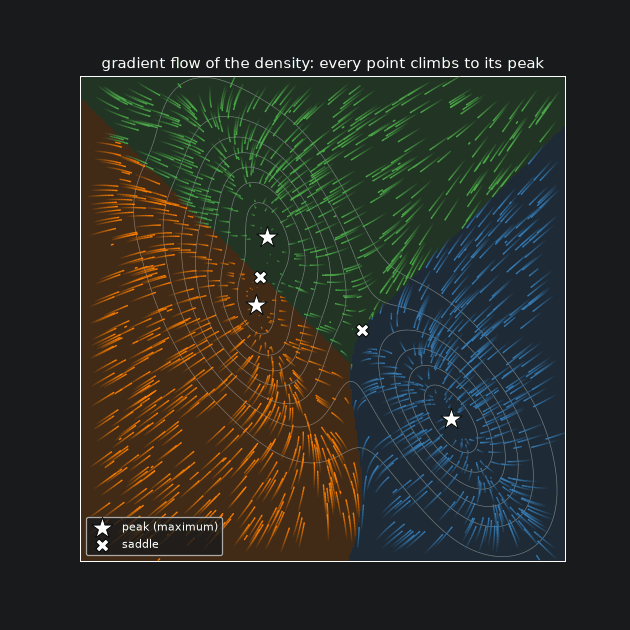

In [5]:
H = len(X) ** (-1 / 6)          # KDE bandwidth: Scott's rule for 2-D data of unit variance
GRID = 300                      # cells per side of the grid the density, regions and critical points are found on
EXTENT = 2.5                    # the figure spans -EXTENT..EXTENT on both axes
N_PARTICLES = 1500
TRAIL = 10                      # positions kept in each particle's trail
DT, STEP = 0.01, 0.03           # flow time per frame, and the most a particle moves in one frame
MAX_AGE = 70                    # frames a particle lives before it starts again at a random place
FLOW_FRAMES, FLOW_FPS = 150, 15
FLOW_GIF = "tomato_gradient_flow.gif"
rng = np.random.default_rng(0)


def kde_terms(P):
    """Offsets from each position in P to every data point, and their Gaussian exponents."""
    d = X[None] - P[:, None]
    return d, -(d ** 2).sum(-1) / (2 * H ** 2)


def log_kde(P, chunk=10_000):
    """log f at each position in P, f the Gaussian KDE of X with bandwidth H."""
    return (np.concatenate([logsumexp(kde_terms(P[s:s + chunk])[1], axis=1) for s in range(0, len(P), chunk)])
            - np.log(len(X) * 2 * np.pi * H ** 2))


def grad_log_kde(P, hessian=False):
    """Gradient of log f at each position in P, and its Hessian if asked.  log f has the critical points of f, of
    the same kinds, and its gradient flow follows the same paths at a different speed."""
    d, e = kde_terms(P)
    w = softmax(e, axis=1)
    m = (w[..., None] * d).sum(1)
    if not hessian:
        return m / H ** 2
    cov = np.einsum("pn,pni,pnj->pij", w, d, d) - m[:, :, None] * m[:, None, :]
    return m / H ** 2, cov / H ** 4 - np.eye(2) / H ** 2


xs = np.linspace(-EXTENT, EXTENT, GRID)
gx, gy = np.meshgrid(xs, xs)
logf = log_kde(np.c_[gx.ravel(), gy.ravel()]).reshape(GRID, GRID)

# Critical points.  Candidates on the grid are the 3x3 local maxima and minima, and saddles, where the neighbors
# around a cell switch between above and below it at least four times; Newton's method on the gradient then places
# each exactly, and the signs of the Hessian's eigenvalues say which kind it is.
inner = np.zeros((GRID, GRID), dtype=bool)
inner[1:-1, 1:-1] = True
ring = [(-1, -1), (-1, 0), (-1, 1), (0, 1), (1, 1), (1, 0), (1, -1), (0, -1)]
above = np.stack([np.roll(logf, (-a, -b), axis=(0, 1)) > logf for a, b in ring])
saddle_like = (above != np.roll(above, 1, axis=0)).sum(axis=0) >= 4
candidate = inner & ((logf == maximum_filter(logf, 3)) | (logf == minimum_filter(logf, 3)) | saddle_like)
crit = np.c_[gx[candidate], gy[candidate]]
for _ in range(30):
    g, hess = grad_log_kde(crit, hessian=True)
    crit = crit - np.linalg.solve(hess, g[..., None])[..., 0]
g, hess = grad_log_kde(crit, hessian=True)
found = (np.linalg.norm(g, axis=1) < 1e-6) & (np.abs(crit) < EXTENT).all(axis=1)
_, first = np.unique(np.round(crit[found], 3), axis=0, return_index=True)
crit, hess = crit[found][np.sort(first)], hess[found][np.sort(first)]
eig = np.linalg.eigvalsh(hess)
crit_kind = np.where((eig < 0).all(axis=1), "peak", np.where((eig > 0).all(axis=1), "minimum", "saddle"))
kde_peaks = crit[crit_kind == "peak"]
print({k: int((crit_kind == k).sum()) for k in ("peak", "saddle", "minimum")})

# Ascending regions: each grid cell steps to its highest 3x3 neighbor until it reaches a local maximum, the grid's
# version of following the gradient, and that maximum is matched to the nearest peak.
padded = np.pad(logf, 1, constant_values=-np.inf)
cells = np.pad(np.arange(GRID * GRID).reshape(GRID, GRID), 1)
shifts = [(a, b) for a in (0, 1, 2) for b in (0, 1, 2)]
best = np.stack([padded[a:a + GRID, b:b + GRID] for a, b in shifts]).argmax(axis=0)
up = np.stack([cells[a:a + GRID, b:b + GRID] for a, b in shifts])
up = np.take_along_axis(up, best[None], axis=0)[0].ravel()
while not np.array_equal(up[up], up):
    up = up[up]
top = np.c_[gx.ravel()[up], gy.ravel()[up]]
region = np.linalg.norm(top[:, None] - kde_peaks[None], axis=2).argmin(axis=1).reshape(GRID, GRID)
region_rgba = np.array([to_rgba(PALETTE[k % len(PALETTE)]) for k in range(len(kde_peaks))])


def region_of(P):
    j = np.clip(np.round((P + EXTENT) / (2 * EXTENT) * (GRID - 1)).astype(int), 0, GRID - 1)
    return region[j[:, 1], j[:, 0]]


# Particles move along the gradient of log f, each at most STEP per frame, and start again at a random place after
# MAX_AGE frames (ages start staggered so they do not all restart at once).
pos = rng.uniform(-EXTENT, EXTENT, (N_PARTICLES, 2))
trail = np.repeat(pos[None], TRAIL, axis=0)       # oldest first
age = rng.integers(0, MAX_AGE, N_PARTICLES)


def advance():
    global pos, trail, age
    step = grad_log_kde(pos) * DT
    step *= np.minimum(1, STEP / np.maximum(np.linalg.norm(step, axis=1), 1e-12))[:, None]
    pos = pos + step
    age += 1
    old = age > MAX_AGE
    pos[old] = rng.uniform(-EXTENT, EXTENT, (old.sum(), 2))
    age[old] = 0
    trail = np.concatenate([trail[1:], pos[None]])
    trail[:, old] = pos[old]


for _ in range(TRAIL):
    advance()

fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(region_rgba[region] * [1, 1, 1, 0] + [0, 0, 0, 0.18], origin="lower",
          extent=(-EXTENT, EXTENT, -EXTENT, EXTENT), interpolation="nearest")
kde = np.exp(logf)
ax.contour(gx, gy, kde, levels=np.linspace(0.08, 0.92, 7) * kde.max(), colors=FG, linewidths=0.5, alpha=0.4)
for k, marker, size, label in (("peak", "*", 320, "peak (maximum)"), ("saddle", "X", 110, "saddle"),
                               ("minimum", "o", 90, "minimum")):
    m = crit_kind == k
    if m.any():
        ax.scatter(*crit[m].T, marker=marker, s=size, color=FG, edgecolors="k", linewidths=0.8, zorder=4,
                   label=label)
trails = LineCollection([], linewidths=1.1, zorder=3)
ax.add_collection(trails)
ax.set(xlim=(-EXTENT, EXTENT), ylim=(-EXTENT, EXTENT), aspect="equal", xticks=(), yticks=())
ax.legend(loc="lower left", fontsize=9)
ax.set_title("gradient flow of the density: every point climbs to its peak", fontsize=12)
fade = (np.arange(1, TRAIL) / (TRAIL - 1))[:, None, None]


def draw_flow(frame):
    advance()
    trails.set_segments(np.stack([trail[:-1], trail[1:]], axis=2).reshape(-1, 2, 2))
    trails.set_color((np.broadcast_to(region_rgba[region_of(pos)], (TRAIL - 1, N_PARTICLES, 4)) * [1, 1, 1, 0]
                      + fade * [0, 0, 0, 1]).reshape(-1, 4))
    return trails,


anim = FuncAnimation(fig, draw_flow, frames=FLOW_FRAMES)
anim.save(FLOW_GIF, writer=PillowWriter(fps=FLOW_FPS), dpi=90)
plt.close(fig)
display(Image(filename=FLOW_GIF))

## Spanning forest

Steps 1–2 on the same density and graph: every point links to its densest neighbor in the graph when that neighbor
is denser than itself, and a point with no denser neighbor is a peak. The links form a spanning forest with one
tree per peak, each drawn in its peak's color (the colors of the persistence GIF), with the peak as a star.

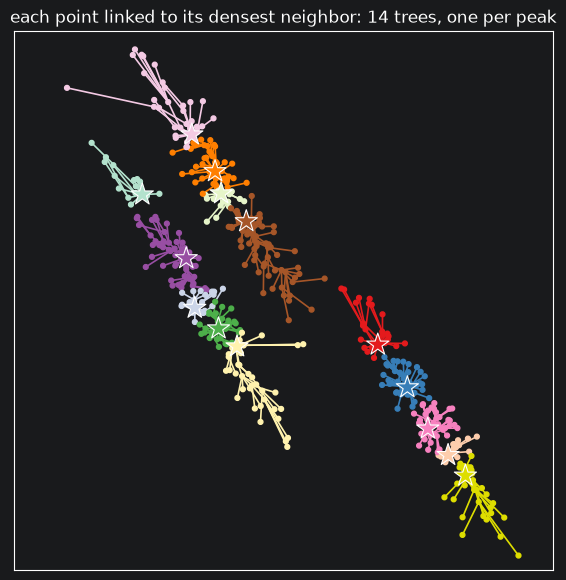

In [6]:
# steps 1-2: each point links to its densest neighbor in the graph when that neighbor is denser; otherwise it is a peak
uphill = np.arange(len(X))
for i in range(len(X)):
    nbrs_i = graph.indices[graph.indptr[i]:graph.indptr[i + 1]]
    j = nbrs_i[np.argmax(density[nbrs_i])]
    if density[j] > density[i]:
        uphill[i] = j
tree_root = uphill.copy()
while not np.array_equal(tree_root[tree_root], tree_root):
    tree_root = tree_root[tree_root]
roots = np.unique(tree_root)
child = np.flatnonzero(uphill != np.arange(len(X)))

fig, ax = plt.subplots(figsize=(7, 7))
ax.add_collection(LineCollection(np.stack([X[child], X[uphill[child]]], axis=1),
                                 colors=[color[r] for r in tree_root[child]], linewidths=1.2))
ax.scatter(X[:, 0], X[:, 1], s=12, color=[color[r] for r in tree_root], zorder=3)
ax.scatter(X[roots, 0], X[roots, 1], marker="*", s=280, color=[color[r] for r in roots], edgecolors=FG,
           linewidths=0.8, zorder=4)
ax.set(xlim=(-2.5, 2.5), ylim=(-2.5, 2.5), aspect="equal", xticks=(), yticks=())
ax.set_title(f"each point linked to its densest neighbor: {len(roots)} trees, one per peak", fontsize=12)
plt.show()

## Merge rule

The test at a vertex v that touches two trees e_j and e_k: merge e_k into e_j if f(r(e_k)) < min{f(r(e_j)), f(v) + τ},
and the same with j and k swapped. Each column is a cross-section through the two roots with v at the saddle between
them. The shaded band reaches τ above f(v), so a root inside it is less prominent than τ: the tree with the lower root
merges only when that root is inside the band.

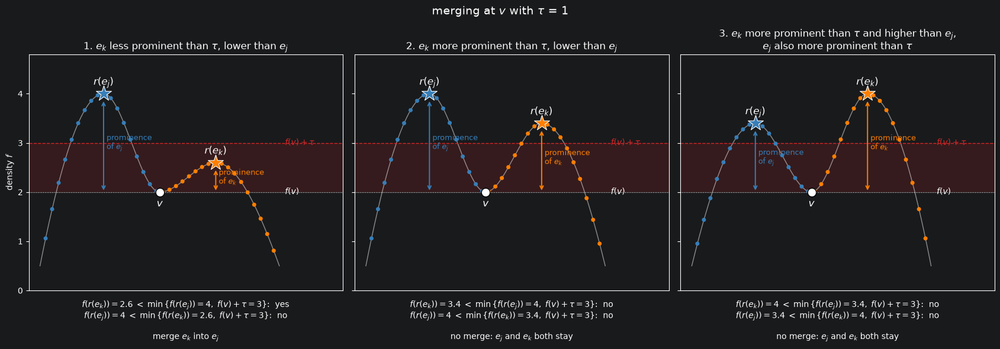

In [9]:
TAU = 1.0
SCENARIOS = [   # (title, f(r(e_j)), f(r(e_k)), f(v))
    ("1. $e_k$ less prominent than $\\tau$, lower than $e_j$", 4.0, 2.6, 2.0),
    ("2. $e_k$ more prominent than $\\tau$, lower than $e_j$", 4.0, 3.4, 2.0),
    ("3. $e_k$ more prominent than $\\tau$ and higher than $e_j$,\n$e_j$ also more prominent than $\\tau$", 3.4, 4.0, 2.0),
]
XJ, XV, XK = 2.0, 3.5, 5.0          # places of r(e_j), v and r(e_k) along a cross-section of the density
EJ_COLOR, EK_COLOR = PALETTE[0], PALETTE[1]


def rule(a, b, fa, fb, fv):
    """The merge test for 'merge e_a into e_b', with its values filled in."""
    return (rf"$f(r(e_{a})) = {fa:g} \;<\; \min\{{f(r(e_{b})) = {fb:g},\; f(v) + \tau = {fv + TAU:g}\}}$:  "
            + ("yes" if fa < min(fb, fv + TAU) else "no"))


fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
for ax, (title, fj, fk, fv) in zip(axes, SCENARIOS):
    curve = PchipInterpolator([0.3, XJ, XV, XK, 6.7], [0.5, fj, fv, fk, 0.5])
    x = np.linspace(0.3, 6.7, 400)
    ax.plot(x, curve(x), color=FG, lw=1, alpha=0.5)
    pts = np.linspace(0.45, 6.55, 36)
    ax.scatter(pts, curve(pts), s=16, color=[EJ_COLOR if p < XV else EK_COLOR for p in pts], zorder=3)
    ax.axhspan(fv, fv + TAU, color="tab:red", alpha=0.15, lw=0)
    ax.axhline(fv, color=FG, ls=":", lw=0.8)
    ax.axhline(fv + TAU, color="tab:red", ls="--", lw=1)
    ax.text(6.85, fv, "$f(v)$", va="center", fontsize=10)
    ax.text(6.85, fv + TAU, "$f(v) + \\tau$", va="center", fontsize=10, color="tab:red")
    for xp, fp, c, name in ((XJ, fj, EJ_COLOR, "j"), (XK, fk, EK_COLOR, "k")):
        ax.scatter(xp, fp, marker="*", s=380, color=c, edgecolors=FG, linewidths=0.8, zorder=5)
        ax.text(xp, fp + 0.18, f"$r(e_{name})$", ha="center", fontsize=12)
        ax.annotate("", xy=(xp, fp - 0.12), xytext=(xp, fv), arrowprops=dict(arrowstyle="<->", color=c, lw=1.4))
        ax.text(xp + 0.08, (fp + fv) / 2, f"prominence\nof $e_{name}$", va="center", fontsize=9, color=c)
    ax.scatter(XV, fv, s=110, color=FG, edgecolors="k", zorder=5)
    ax.text(XV, fv - 0.3, "$v$", ha="center", fontsize=12)
    if fk < min(fj, fv + TAU):
        outcome = "merge $e_k$ into $e_j$"
    elif fj < min(fk, fv + TAU):
        outcome = "merge $e_j$ into $e_k$"
    else:
        outcome = "no merge: $e_j$ and $e_k$ both stay"
    ax.text(0.5, -0.04, f"{rule('k', 'j', fk, fj, fv)}\n{rule('j', 'k', fj, fk, fv)}\n\n{outcome}",
            transform=ax.transAxes, ha="center", va="top", fontsize=10)
    ax.set(xlim=(0, 8.4), ylim=(0, 4.8), xticks=())
    ax.set_title(title, fontsize=12)
axes[0].set_ylabel("density $f$")
fig.suptitle(f"merging at $v$ with $\\tau$ = {TAU:g}", fontsize=14)
fig.tight_layout()
plt.show()

## What should τ be?

A noisier version of the data: the same three sheared blobs, wider (`NOISY_STD`), plus `N_UNIFORM` points spread
uniformly over them, with the same density and graph settings. The three blobs are still the three most prominent
peaks, but other peaks come close to the third, so no τ cleanly separates the clusters from the noise. The second
row cuts at the τ that keeps the three blobs, the middle of the gap between the third and fourth most prominent
peaks; the shaded band is every τ that gives the same clusters.

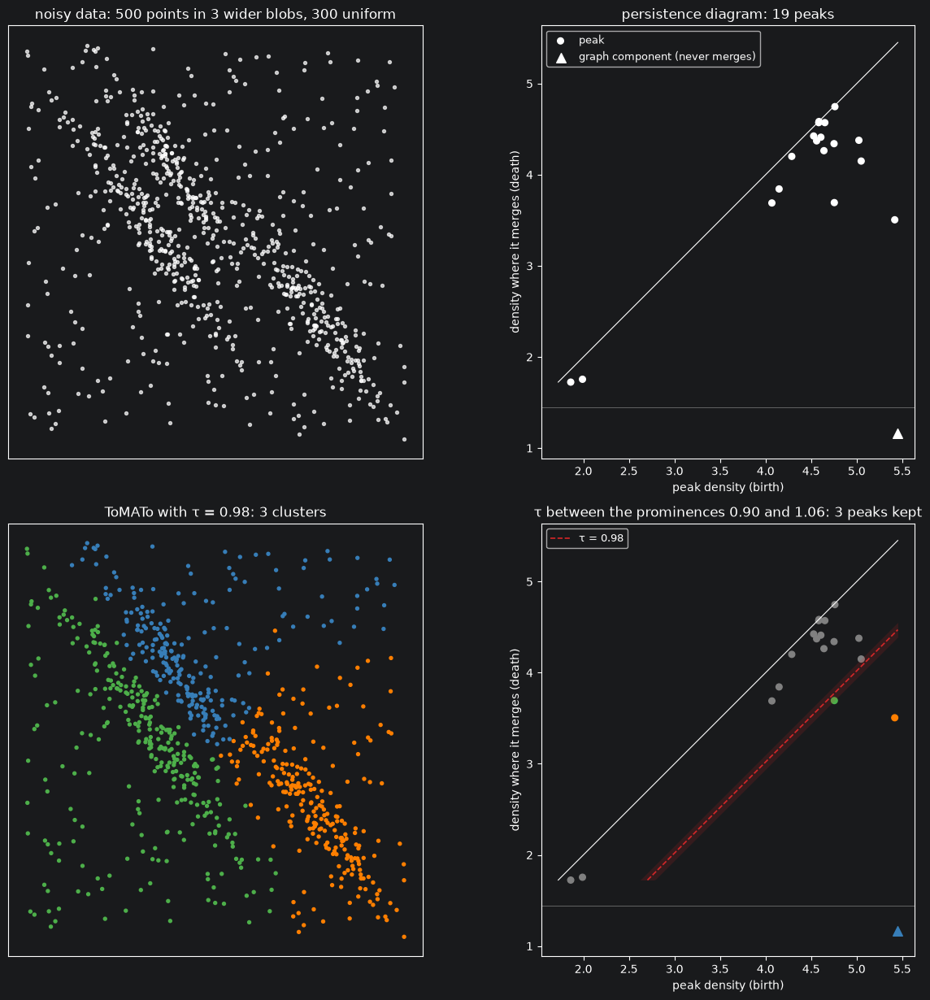

In [11]:
NOISY_STD = 1.4         # spread of each blob (the clean data uses scikit-learn's default, 1.0)
N_UNIFORM = 300         # points spread uniformly over the blobs' bounding box
N_CLUSTERS = 3          # clusters the second row's tau leaves
noise_rng = np.random.default_rng(3)

blobs, _ = datasets.make_blobs(n_samples=N_SAMPLES, random_state=170, cluster_std=NOISY_STD)
blobs = blobs @ np.array([[0.6, -0.6], [-0.4, 0.8]])
X_noisy = StandardScaler().fit_transform(
    np.r_[blobs, noise_rng.uniform(blobs.min(axis=0), blobs.max(axis=0), (N_UNIFORM, 2))])


def tomato_pass(P, tau=np.inf):
    """ToMATo on P's log-DTM density and K_GRAPH-neighbor graph.  Each point joins the tree of its densest neighbor
    above it; where it touches another tree, the tree with the lower root merges into the other if that root is
    less than tau above the point.  Returns the density, each point's root, and for every peak the density where it
    merged (-inf if it never did).  With tau = inf every merge happens: the pass the persistence GIF animates."""
    dens = log_dtm(P, K_DENS)
    nb = cKDTree(P).query(P, k=K_GRAPH + 1)[1][:, 1:]
    A = sp.csr_matrix((np.ones(nb.size), nb.ravel(), np.arange(0, nb.size + 1, K_GRAPH)), shape=(len(P), len(P)))
    G = (A + A.T).tocsr()
    up = np.full(len(P), -1)

    def root(i):
        while up[i] != i:
            up[i] = up[up[i]]
            i = up[i]
        return i

    merged_at = {}
    for i in np.argsort(-dens, kind="stable"):
        up[i] = i
        above = [j for j in G.indices[G.indptr[i]:G.indptr[i + 1]] if up[j] >= 0]
        if not above:
            merged_at[i] = -np.inf
            continue
        up[i] = root(max(above, key=lambda j: dens[j]))
        for j in above:
            ri, rj = root(i), root(j)
            if ri != rj:
                high, low = (ri, rj) if dens[ri] > dens[rj] else (rj, ri)
                if dens[low] < dens[i] + tau:
                    up[low] = high
                    merged_at[low] = dens[i]
    return dens, np.array([root(i) for i in range(len(P))]), merged_at


dens_n, _, merged_at = tomato_pass(X_noisy)
tops = np.array(list(merged_at))
birth_n, death_n = dens_n[tops], np.array([merged_at[p] for p in tops])
never = ~np.isfinite(death_n)
lo_n, hi_n = min(death_n[~never].min(), birth_n.min()), birth_n.max()
pad_n = 0.05 * (hi_n - lo_n)
strip = lo_n - 3 * pad_n        # height of the strip for never-merging peaks, below every death

# tau in the middle of the gap between the prominences of the last peak kept and the first merged
prom = np.sort((birth_n - death_n)[~never])[::-1]
keep = N_CLUSTERS - never.sum()
tau_lo, tau_hi = prom[keep], prom[keep - 1]
tau_n = (tau_lo + tau_hi) / 2
_, roots_n, _ = tomato_pass(X_noisy, tau_n)
cluster_ids = np.unique(roots_n)
if cluster_ids.size != N_CLUSTERS:
    raise ValueError(f"tau {tau_n:.3f} left {cluster_ids.size} clusters, not {N_CLUSTERS}")
cluster_color = {r: PALETTE[k] for k, r in enumerate(cluster_ids[np.argsort(-dens_n[cluster_ids])])}


def noisy_diagram(ax, tau=None):
    """The noisy data's persistence diagram; with tau, the tau line, the band of tau leaving the same clusters, and
    the kept peaks in their clusters' colors."""
    kept = (birth_n - death_n > tau) if tau is not None else np.zeros(len(tops), dtype=bool)
    shade = np.array([to_rgba(cluster_color[p] if k else (FG if tau is None else "0.5")) for p, k in zip(tops, kept)])
    ax.plot([lo_n, hi_n], [lo_n, hi_n], color=FG, lw=0.8)
    ax.axhline(strip + 1.5 * pad_n, color="0.5", lw=0.5)
    ax.scatter(birth_n[~never], death_n[~never], s=30, color=shade[~never], label=None if tau is not None else "peak")
    ax.scatter(birth_n[never], np.full(never.sum(), strip), marker="^", s=70, color=shade[never],
               label=None if tau is not None else "graph component (never merges)")
    if tau is not None:
        x = np.linspace(lo_n, hi_n, 200)
        ax.fill_between(x, np.maximum(x - tau_hi, lo_n), np.maximum(x - tau_lo, lo_n), color="tab:red", alpha=0.15,
                        lw=0)
        ax.plot([lo_n + tau, hi_n], [lo_n, hi_n - tau], color="tab:red", ls="--", lw=1.2, label=f"τ = {tau:.2f}")
    ax.set(xlim=(lo_n - pad_n, hi_n + pad_n), ylim=(strip - 1.5 * pad_n, hi_n + pad_n), aspect="equal",
           xlabel="peak density (birth)", ylabel="density where it merges (death)")
    ax.legend(loc="upper left", fontsize=9)


fig, axes = plt.subplots(2, 2, figsize=(13, 12.4))
axes[0, 0].scatter(*X_noisy.T, s=8, color=FG, alpha=0.7)
axes[0, 0].set_title(f"noisy data: {N_SAMPLES} points in 3 wider blobs, {N_UNIFORM} uniform", fontsize=12)
noisy_diagram(axes[0, 1])
axes[0, 1].set_title(f"persistence diagram: {len(tops)} peaks", fontsize=12)
axes[1, 0].scatter(*X_noisy.T, s=8, color=[cluster_color[r] for r in roots_n])
axes[1, 0].set_title(f"ToMATo with τ = {tau_n:.2f}: {N_CLUSTERS} clusters", fontsize=12)
noisy_diagram(axes[1, 1], tau_n)
axes[1, 1].set_title(f"τ between the prominences {tau_lo:.2f} and {tau_hi:.2f}: {N_CLUSTERS} peaks kept",
                     fontsize=12)
for ax in axes[:, 0]:
    ax.set(aspect="equal", xticks=(), yticks=())
fig.tight_layout()
plt.show()